# Tennis head-to-head stats in Python (ATP & WTA)

Pulls a head-to-head record and a player's recent form into pandas with the
[Tennis Player Stats & H2H Scraper](https://apify.com/incognito_mode/tennis-player-stats-h2h-scraper)
on Apify (data from Sofascore).

Set `APIFY_TOKEN` in your environment before starting Jupyter
([where to find it](https://console.apify.com/settings/integrations)). Each run
prints what it cost; this whole notebook comes to about $0.55.

In [1]:
from datetime import date

import pandas as pd

from career import plot_first_serve, plot_win_rate, win_rate_by_surface
from common import matches_frame, run_actor

## 1. One head-to-head

One input line per pair. Names, Sofascore IDs and Sofascore player links all work.

In [2]:
rows = run_actor({"matchups": ["Sinner vs Alcaraz"]})
summary = next(r for r in rows if r["rowType"] == "h2h")
a, b = summary["playerA"]["name"], summary["playerB"]["name"]
print(f"{a} {summary['playerAWins']}-{summary['playerBWins']} {b} ({summary['totalMeetings']} meetings)")

Run SUCCEEDED: 19 rows, cost $0.045
Jannik Sinner 7-11 Carlos Alcaraz (18 meetings)


The summary row is free and already split by surface:

In [3]:
pd.DataFrame(summary["bySurface"]).T.rename(columns={"playerAWins": a, "playerBWins": b})

,Jannik Sinner,Carlos Alcaraz
hard,3,8
grass,2,0
clay,2,3


Every meeting is its own row, written from the first-named player's side.
`scoreForPlayer` reads from that side too; `result_type` flags retirements and walkovers.

In [4]:
meetings = matches_frame(rows)
meetings.tail(5).assign(date=lambda d: d["date"].dt.date)[
    ["date", "tournament", "round", "surface", "won", "score", "result_type"]
]

,date,tournament,round,surface,won,score,result_type
13,2025-07-13,"Wimbledon, Men",Final,grass,True,4-6 6-4 6-4 6-4,completed
14,2025-08-18,Cincinnati,Final,hard,False,0-5,retired
15,2025-09-07,"US Open, Men",Final,hard,False,2-6 6-3 1-6 4-6,completed
16,2025-11-16,ATP Finals,Final,hard,True,7-6(4) 7-5,completed
17,2026-04-12,Monte Carlo,Final,clay,True,7-6(5) 6-3,completed


## 2. A player's form, this season and last

`maxMatchesPerPlayer: 0` means no cap, and `dateFrom` keeps it to whole seasons.
`matchDetails: ["statistics"]` adds serve and return stats to every match.

In [5]:
since = f"{date.today().year - 1}-01-01"
rows = run_actor({
    "players": ["Iga Swiatek"],
    "maxMatchesPerPlayer": 0,
    "dateFrom": since,
    "matchDetails": ["statistics"],
})
df = matches_frame(rows)
df["season"] = df["date"].dt.year
name = df["player"].iloc[0]
print(f"{name}: {len(df)} matches since {since}, {df['won'].mean():.0%} won")

Run SUCCEEDED: 139 rows, cost $0.486
Iga Swiatek: 139 matches since 2025-01-01, 76% won


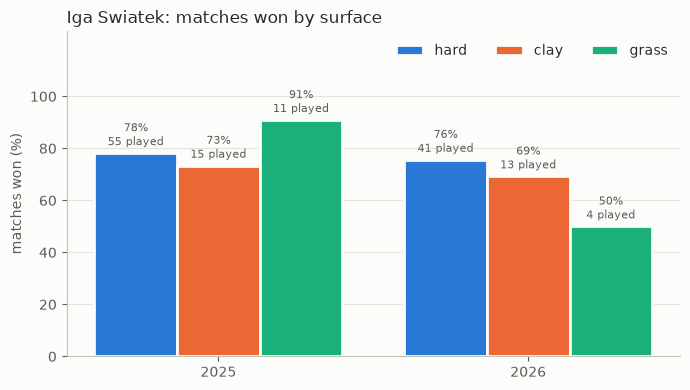

In [6]:
rate, count = win_rate_by_surface(df)
plot_win_rate(name, rate, count)

The statistics keep Sofascore's home/away order (`player1` is the home player),
so `common.stat_for_player` picks the side that matches `perspectivePlayer`.

138 matches with statistics


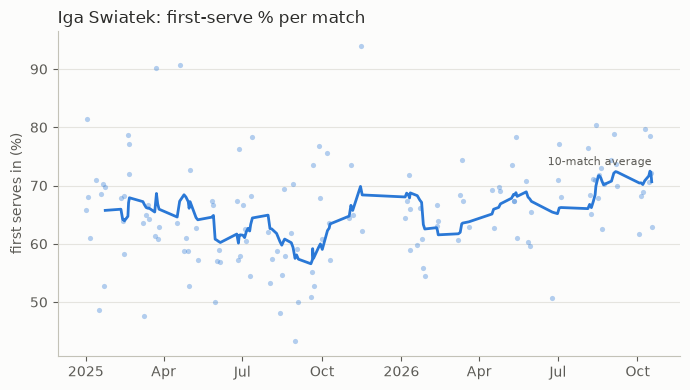

In [7]:
n = plot_first_serve(name, rows)
print(f"{n} matches with statistics")